# Module 4 — The Central Limit Theorem

**Probability Simulation Laboratory** · Module 4 of 8

## Learning objectives
1. state the Lindeberg–Lévy CLT and its assumptions precisely;
2. distinguish the *distribution of the data* from the *sampling distribution of the mean*;
3. measure how quickly the standardised mean approaches normality and why skewness slows it;
4. see what happens when the assumptions fail (infinite variance, extreme heavy tails);
5. connect the CLT to confidence intervals and their *actual* coverage.

## Research objective
Investigate how the distribution of standardised sample means approaches a normal distribution under appropriate conditions.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "04_central_limit_theorem" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import clt                                  # 04_central_limit_theorem/src/clt.py

## 1. Mathematical background

**Theorem (Lindeberg–Lévy CLT).** Let $X_1,X_2,\dots$ be i.i.d. with $\mathbb EX_i=\mu$ and $0<\sigma^2=\operatorname{Var}X_i<\infty$. Then
$$Z_n=\frac{\sqrt n(\bar X_n-\mu)}{\sigma}\ \xrightarrow{d}\ \mathcal N(0,1),\qquad\text{i.e.}\quad P(Z_n\le z)\to\Phi(z)\ \text{for all }z.$$
Symbols: $\bar X_n$ sample mean; $\sigma/\sqrt n$ the **standard error**; $\xrightarrow{d}$ convergence in distribution; $\Phi$ the standard normal cdf.

**Proof sketch (characteristic functions).** Put $Y_i=(X_i-\mu)/\sigma$ (mean 0, variance 1) with characteristic function $\varphi(t)=1-\tfrac{t^2}2+o(t^2)$. Then $Z_n=\frac1{\sqrt n}\sum Y_i$ has
$\varphi_{Z_n}(t)=\varphi(t/\sqrt n)^n=\big(1-\tfrac{t^2}{2n}+o(1/n)\big)^n\to e^{-t^2/2}$, the characteristic function of $\mathcal N(0,1)$. Lévy's continuity theorem completes the argument. $\square$

**Assumptions that matter:** independence, identical distribution (relaxed by Lindeberg's condition), and **finite variance**. Nothing is assumed about the shape of the data distribution — that is why the theorem is powerful.

**Speed of convergence (Berry–Esseen).** With $\rho=\mathbb E|X-\mu|^3<\infty$,
$$\sup_z|P(Z_n\le z)-\Phi(z)|\ \le\ \frac{C\rho}{\sigma^3\sqrt n},\qquad C\le0.4748.$$
A finer (Edgeworth) expansion shows the leading correction is driven by skewness $\gamma$: $P(Z_n\le z)=\Phi(z)-\frac{\gamma}{6\sqrt n}(z^2-1)\varphi(z)+O(1/n)$, and the *skewness of $Z_n$ itself equals $\gamma/\sqrt n$*. Skewed data therefore need larger $n$.

**Infinite variance.** If $\operatorname{Var}X=\infty$ the CLT does not apply. For heavy tails with index $\alpha\in(0,2)$ (e.g. Student $t_\alpha$), properly normalised averages converge instead to *stable* laws, with $\bar X_n$ scaling like $n^{1/\alpha-1}$ (slower than $n^{-1/2}$); for Cauchy ($\alpha=1$) the scaling exponent is $0$.

**Confidence interval for a mean.** $\bar X_n\pm t_{n-1,0.975}\,s/\sqrt n$ has nominal 95% coverage; the CLT justifies it *asymptotically*, and for small $n$ and skewed data its actual coverage can be lower (Experiment 4.4).

## Experiment 4.1

**A. Experiment title.** Distribution of the standardised sample mean $Z_n=\sqrt n(\bar X_n-\mu)/\sigma$ for Uniform, Exponential, Bernoulli(0.1) and Lognormal(0,1) data, $n\in\{1,5,30,200\}$.

**B. Research question.** How does the shape of the sampling distribution of the mean change with the sample size and the shape of the underlying distribution?

**C. Mathematical foundation.**

$Z_n$ has mean $0$, variance $1$ for every $n$ (exactly, from independence) and tends to $\mathcal N(0,1)$. At $n=1$, $Z_1=(X-\mu)/\sigma$ has the *data's* shape. Distributions with larger skewness
(Lognormal: $\gamma\approx6.2$; Exponential: $2$; Bernoulli(0.1): $2.67$; Uniform: $0$) approach normality more slowly.

**D. Theoretical prediction.**

Uniform: bell-shaped already for $n\approx5$. Exponential and Bernoulli(0.1): visibly skewed at $n=5$, close to normal by $n=30$–$200$. Lognormal: still visibly right-skewed at $n=30$, reasonable by $n=200$.

**E. Experimental design.**

For each distribution and $n\in\{1,5,30,200\}$ generate $50{,}000$ independent standardised means (using the *true* $\mu,\sigma$) and plot histograms with the $\mathcal N(0,1)$ density.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

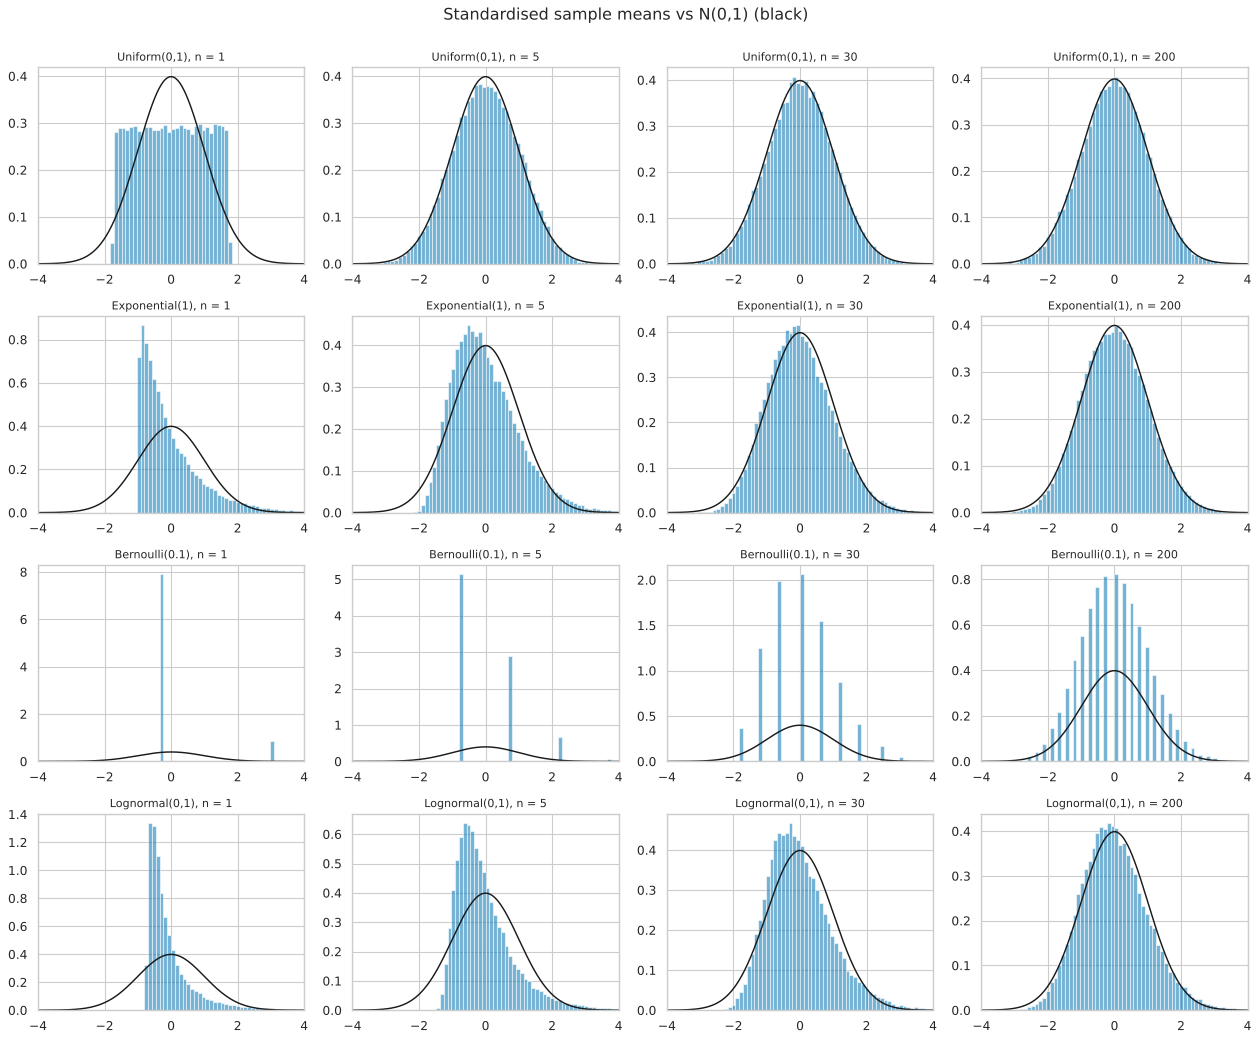

PosixPath('/home/claude/probability-simulation-laboratory/04_central_limit_theorem/results/exp4_1_clt_grid.png')

In [3]:
# F. Implementation ------------------------------------------------------------------
# Z_n = sqrt(n) (Xbar_n - mu)/sigma   ->  clt.standardized_means(draw, mu, sigma, n, reps, rng)
laws = {
    "Uniform(0,1)": stats.uniform(0, 1),
    "Exponential(1)": stats.expon(),
    "Bernoulli(0.1)": stats.bernoulli(0.1),
    "Lognormal(0,1)": stats.lognorm(s=1.0),
}
reps = 50_000
n_show = [1, 5, 30, 200]
setup = {name: clt.from_frozen(dist) for name, dist in laws.items()}

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
grid = np.linspace(-4, 4, 400)
for i, (name, (draw, mu, sigma)) in enumerate(setup.items()):
    for j, n in enumerate(n_show):
        z = clt.standardized_means(draw, mu, sigma, n, reps, rng)
        ax = axes[i, j]
        ax.hist(z, bins=70, range=(-4, 4), density=True, alpha=0.55)
        ax.plot(grid, stats.norm.pdf(grid), "k", lw=1.3)
        ax.set_title(f"{name}, n = {n}", fontsize=10)
        ax.set_xlim(-4, 4)
fig.suptitle("Standardised sample means vs N(0,1) (black)", y=1.0)
fig.tight_layout(); save_fig(fig, RESULTS, "exp4_1_clt_grid.png")

In [4]:
# G/H. KS distance to N(0,1) and the Berry-Esseen bound ------------------------------------
n_list = [1, 2, 5, 10, 30, 100, 300, 1000]
rows = []
for name, dist in laws.items():
    draw, mu, sigma = setup[name]
    rho = dist.expect(lambda x: np.abs(x - mu) ** 3)                      # E|X-mu|^3
    skew = float(dist.stats(moments="s"))
    for n in n_list:
        z = clt.standardized_means(draw, mu, sigma, n, reps, rng)
        rows.append(dict(distribution=name, n=n, KS_distance=clt.ks_distance_to_normal(z), BerryEsseen_bound=min(1.0, 0.4748 * rho / (sigma**3 * np.sqrt(n))),
                         sample_skew_times_sqrt_n=float(stats.skew(z)) * np.sqrt(n), data_skewness=skew, z_mean=z.mean(), z_var=z.var()))
ks_table = pd.DataFrame(rows)
ks_table.to_csv(RESULTS / "exp4_1_ks_table.csv", index=False)
floor = np.sqrt(np.log(40) / (2 * reps))
print(f"Monte Carlo noise floor of the KS distance with {reps:,} replications (DKW 95%): {floor:.4f}")
display(ks_table.pivot(index="n", columns="distribution", values="KS_distance").round(4))

Monte Carlo noise floor of the KS distance with 50,000 replications (DKW 95%): 0.0061


distribution,Bernoulli(0.1),Exponential(1),"Lognormal(0,1)","Uniform(0,1)"
n,,,,
1,0.5297,0.1587,0.2291,0.0594
2,0.4916,0.0967,0.1655,0.0186
5,0.3651,0.0631,0.1179,0.0087
10,0.2368,0.0433,0.0895,0.0051
30,0.1473,0.0252,0.0593,0.0032
100,0.0832,0.0130,0.0371,0.0039
300,0.0465,0.0102,0.0238,0.0053
1000,0.0263,0.0034,0.0148,0.0026


**H. Theoretical versus empirical comparison.**

The histograms move from the data's shape at $n=1$ toward the bell curve as $n$ grows, fastest for the Uniform. In the KS table the distance falls with $n$ for every distribution but at very different paces: at $n=30$ it is about $0.003$ for the Uniform (already at the noise floor), $0.025$ for the Exponential, $0.059$ for the Lognormal and $0.147$ for Bernoulli(0.1);
and once it reaches the Monte Carlo noise floor ($\approx0.006$) it stops decreasing.
In `ks_table.csv`, $\sqrt n\cdot\operatorname{skew}(Z_n)$ is close to the data skewness $\gamma$ (Exponential: $1.9$, $2.2$, $1.8$ at $n=100,300,1000$ against $\gamma=2$; Lognormal: $6.1$, $6.6$, $5.9$ against $6.18$), and the mean and variance of $Z_n$ are $\approx0$ and $\approx1$. The Berry–Esseen bound is far above the observed distance (e.g. Lognormal at $n=100$: bound $0.30$, observed $0.037$): valid but pessimistic.

**I. Interpretation.**

Normality of the *mean* arises from averaging, not from the data being normal. The practical question is not "is $n\ge30$?" (a folklore rule) but "how skewed/heavy-tailed is the data?": the Lognormal at $n=30$ is still visibly skewed.

**J. Limitations.**

KS distances smaller than the noise floor ($\approx0.006$) cannot be distinguished from $0$ with $50{,}000$ replications. The standardisation uses the *true* $\sigma$; with an estimated $\sigma$ (Student's $t$) small-$n$ behaviour differs (Experiment 4.4). The Bernoulli(0.1) case is a lattice distribution: $Z_n$ takes only $n+1$ values, so its cdf has jumps and the KS distance can never be smaller than about half the largest jump, roughly $0.2/\sqrt{np(1-p)}$ (about $0.02$ at $n=1000$). This lattice effect decays only like $n^{-1/2}$ and is why Bernoulli(0.1) still has a KS distance of $0.026$ at $n=1000$.

**K. Research conclusion.**

The sampling distribution of the mean approaches $\mathcal N(0,1)$ after standardisation, at a rate controlled by skewness and tail weight.

**L. Further investigation.**

Study the sum of $n$ independent *non-identically* distributed variables (Lindeberg's condition) — e.g. Bernoulli($p_i$) with $p_i$ varying — and compare the convergence speed.

## Experiment 4.2

**A. Experiment title.** Rate of convergence: Kolmogorov distance $\sup_z|F_{Z_n}(z)-\Phi(z)|$ versus $n$ (log-log), and the skewness law $\operatorname{skew}(Z_n)=\gamma/\sqrt n$.

**B. Research question.** At what rate does the sampling distribution become normal, and is the rate the same for all distributions?

**C. Mathematical foundation.**

Berry–Esseen gives an $O(n^{-1/2})$ upper bound. For skewed data the first Edgeworth correction is of order $\gamma/\sqrt n$, so the distance is of order $n^{-1/2}$ (slope $-\tfrac12$). For symmetric data ($\gamma=0$) the leading term vanishes and the distance is $O(1/n)$ (slope $-1$) — until the Monte Carlo floor is reached.

**D. Theoretical prediction.**

Exponential and Lognormal: slope near $-0.5$ before the noise floor; Uniform: faster decay, flattening at the floor around $n\approx10$–$30$. $\sqrt n\cdot\operatorname{skew}(Z_n)\to\gamma$ (Exponential: $2$).

**E. Experimental design.**

Use the KS table from Experiment 4.1 (reps $=50{,}000$): fit log-log slopes over the range of $n$ where the distance exceeds twice the noise floor, and plot all four curves with the Berry–Esseen bound for the Exponential.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,points_above_floor,fitted_slope
distribution,,
"Uniform(0,1)",2,NaN
Exponential(1),6,-0.52948
Bernoulli(0.1),8,-0.45482
"Lognormal(0,1)",8,-0.39217


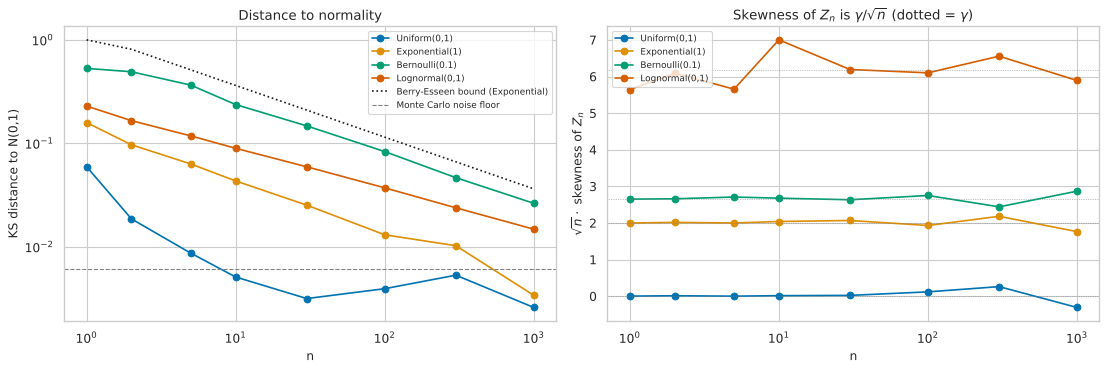

In [5]:
# F/G. Implementation and results ----------------------------------------------------------
floor = np.sqrt(np.log(40) / (2 * reps))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
slope_rows = []
for name in laws:
    sub = ks_table[ks_table.distribution == name]
    ax[0].plot(sub.n, sub.KS_distance, "o-", label=name)
    usable = sub[sub.KS_distance > 2 * floor]
    if len(usable) >= 3:
        slope = np.polyfit(np.log(usable.n), np.log(usable.KS_distance), 1)[0]
    else:
        slope = np.nan
    slope_rows.append(dict(distribution=name, points_above_floor=len(usable), fitted_slope=slope))
sub_e = ks_table[ks_table.distribution == "Exponential(1)"]
ax[0].plot(sub_e.n, sub_e.BerryEsseen_bound, "k:", label="Berry-Esseen bound (Exponential)")
ax[0].axhline(floor, color="grey", ls="--", lw=1, label="Monte Carlo noise floor")
ax[0].set(xscale="log", yscale="log", xlabel="n", ylabel="KS distance to N(0,1)", title="Distance to normality"); ax[0].legend(fontsize=8)

for name in laws:
    sub = ks_table[ks_table.distribution == name]
    ax[1].plot(sub.n, sub.sample_skew_times_sqrt_n, "o-", label=name)
    ax[1].axhline(float(laws[name].stats(moments="s")), lw=0.6, ls=":", color="grey")
ax[1].set(xscale="log", xlabel="n", ylabel=r"$\sqrt{n}\cdot$ skewness of $Z_n$", title=r"Skewness of $Z_n$ is $\gamma/\sqrt{n}$ (dotted = $\gamma$)"); ax[1].legend(fontsize=8)
fig.tight_layout(); save_fig(fig, RESULTS, "exp4_2_rate.png")
slopes = pd.DataFrame(slope_rows).set_index("distribution")
slopes.to_csv(RESULTS / "exp4_2_slopes.csv")
display(slopes)

**H. Theoretical versus empirical comparison.**

Fitted slopes (using only points above twice the noise floor): Exponential $-0.53$, Bernoulli(0.1) $-0.45$ (lattice effect included), Lognormal $-0.39$; for the Uniform only two points lie above the floor, so no slope is estimated — its curve simply drops steeply to the floor. The Lognormal's shallower slope is expected: its Berry–Esseen constant $\rho/\sigma^3$ is large, so it is still in the pre-asymptotic regime over this range of $n$. The right panel shows $\sqrt n\,\operatorname{skew}(Z_n)$ hovering near each distribution's skewness $\gamma$ (dotted lines); the scatter, especially for the Lognormal, shows how noisy the sample skewness of a heavy-tailed variable is (cf. Module 2).

**I. Interpretation.**

Skewness is the first-order obstacle to normality. This rule predicts the *required* $n$: to make the skewness of the mean below $0.1$ one needs $n\ge(\gamma/0.1)^2$: $400$ for the Exponential, over $3{,}800$ for the Lognormal(0,1).

**J. Limitations.**

The fitted slopes use few points and a restricted range, so they are rough; only the qualitative contrast (slow for skewed, fast for symmetric) should be trusted. The Berry–Esseen constant and bound are for the *worst* case.

**K. Research conclusion.**

Convergence to normality is $O(n^{-1/2})$ for skewed data and faster for symmetric data; $\operatorname{skew}(Z_n)=\gamma/\sqrt n$ is confirmed.

**L. Further investigation.**

Use the Edgeworth expansion to predict the Exponential's $P(Z_n\le z)$ and compare the correction with simulation.

## Experiment 4.3

**A. Experiment title.** Heavy tails: Student $t_3$ (finite variance, infinite 4th moment), Student $t_{1.5}$ (infinite variance) and Cauchy — scaling of the interquartile range of $\bar X_n$.

**B. Research question.** What happens to the sampling distribution of the mean when the variance is infinite?

**C. Mathematical foundation.**

$t_3$ has $\sigma^2=3$: the CLT applies, though slowly since $\mathbb E X^4=\infty$. For $t_\alpha$ with $\alpha<2$, $\operatorname{Var}=\infty$ and $\bar X_n\cdot n^{1-1/\alpha}$ converges to a stable law, so the *spread* of $\bar X_n$ scales like $n^{1/\alpha-1}$:
$n^{-1/3}$ for $\alpha=1.5$, $n^{-1/2}$ for finite variance, and $n^{0}$ for Cauchy ($\alpha=1$). The interquartile range (IQR) exists regardless of moments and is a convenient spread measure.

**D. Theoretical prediction.**

Log-log slope of $\operatorname{IQR}(\bar X_n)$ versus $n$: about $-0.5$ for $t_3$, about $-0.33$ for $t_{1.5}$, about $0$ for Cauchy (IQR $=2$ at every $n$).

**E. Experimental design.**

$n\in\{1,3,10,30,100,300,1000\}$; $20{,}000$ replications; also QQ-plots of $Z_{100}$ for Exponential, Lognormal and $t_3$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

In [6]:
# F. Implementation ------------------------------------------------------------------
heavy = {"Student t(3)": stats.t(3), "Student t(1.5)": stats.t(1.5), "Cauchy": stats.cauchy()}
n_list = [1, 3, 10, 30, 100, 300, 1000]
reps_h = 20_000
rows = []
iqr_tab = {}
for name, dist in heavy.items():
    draw = lambda r, size, dist=dist: dist.rvs(size=size, random_state=r)
    vals = [clt.iqr(clt.sample_means(draw, n, reps_h, rng)) for n in n_list]
    iqr_tab[name] = vals
    rows.append(dict(distribution=name, fitted_slope=np.polyfit(np.log(n_list), np.log(vals), 1)[0],
                     predicted_slope={"Student t(3)": -0.5, "Student t(1.5)": 1 / 1.5 - 1, "Cauchy": 0.0}[name]))
iqr_df = pd.DataFrame(iqr_tab, index=pd.Index(n_list, name="n"))
iqr_df.to_csv(RESULTS / "exp4_3_iqr.csv")
display(iqr_df.round(4))
display(pd.DataFrame(rows).set_index("distribution"))

,Student t(3),Student t(1.5),Cauchy
n,,,
1,1.5280,1.7451,2.0271
3,1.0284,1.4421,1.9924
10,0.6401,1.0716,1.9684
30,0.3914,0.8085,1.9931
100,0.2193,0.5711,1.9853
300,0.1327,0.4121,2.0371
1000,0.0732,0.2797,2.0071


,fitted_slope,predicted_slope
distribution,,
Student t(3),-0.44313,-0.50000
Student t(1.5),-0.26771,-0.33333
Cauchy,0.00070,0.00000


,P_abs_Z_gt_3,normal_value,skewness
case,,,
"Exponential(1), n=100",0.00305,0.0027,0.19418
"Lognormal(0,1), n=100",0.00670,0.0027,0.69863
"Student t(3), n=100",0.00615,0.0027,-0.03173


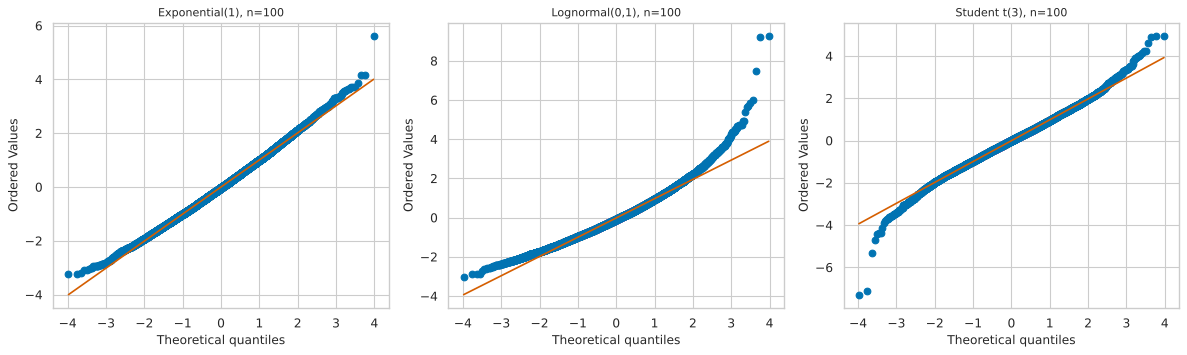

In [7]:
# G. QQ-plots of standardised means against the normal ---------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
cases = [("Exponential(1), n=100", *setup["Exponential(1)"], 100), ("Lognormal(0,1), n=100", *setup["Lognormal(0,1)"], 100),
         ("Student t(3), n=100", lambda r, size: stats.t(3).rvs(size=size, random_state=r), 0.0, np.sqrt(3.0), 100)]
tail_rows = []
for ax, (title, draw, mu, sigma, n) in zip(axes, cases):
    z = clt.standardized_means(draw, mu, sigma, n, 20_000, rng)
    stats.probplot(z, dist="norm", plot=ax)
    ax.set_title(title, fontsize=10)
    tail_rows.append(dict(case=title, P_abs_Z_gt_3=clt.prob_beyond(z, 3.0), normal_value=2 * stats.norm.sf(3), skewness=stats.skew(z)))
fig.tight_layout(); save_fig(fig, RESULTS, "exp4_3_qqplots.png")
display(pd.DataFrame(tail_rows).set_index("case"))

**H. Theoretical versus empirical comparison.**

The Cauchy IQR stays at $2.0\pm0.05$ for every $n$ from $1$ to $1000$ (fitted slope $0.0007$): averaging does nothing. The fitted slopes are $-0.44$ for $t_3$ (prediction $-0.5$) and $-0.27$ for $t_{1.5}$ (prediction $-0.33$). Both fall slightly short of the asymptotic exponents because the small-$n$ points are not yet in the asymptotic regime: for $t_3$ the value at $n=1000$ is $0.0732$, very close to the Gaussian prediction $1.349\sqrt3/\sqrt{1000}=0.0739$, so the convergence has taken hold at large $n$; $t_{1.5}$ approaches its stable-law scaling more slowly.
In the QQ-plots at $n=100$ the Exponential is close to the line with slight curvature, the Lognormal is visibly bowed (right skew; sample skewness $0.70$), and the $t_3$ deviates in the extreme tails. $P(|Z_{100}|>3)$ is $0.0031$ (Exponential), $0.0067$ (Lognormal) and $0.0062$ ($t_3$) against the normal value $0.0027$ — more than twice as large for the last two.

**I. Interpretation.**

When the variance is infinite the "$\sqrt n$" in the CLT is simply the wrong normalisation: the sample mean converges faster than nothing (Cauchy: not at all) but slower than $n^{-1/2}$. Even when $\sigma^2<\infty$ (as for $t_3$), heavy tails make the normal approximation poor *in the tails* — exactly where risk measures live.

**J. Limitations.**

The IQR is insensitive to the tails we care about; fitted slopes at $n\le1000$ are approximate; for the stable-law claims we relied on theory rather than testing the limit law itself.

**K. Research conclusion.**

CLT scaling depends on tail index: $n^{-1/2}$ (finite variance), $n^{1/\alpha-1}$ (stable regime), $n^0$ (Cauchy). Heavy tails undermine normal approximations in the tails even with finite variance.

**L. Further investigation.**

Estimate the tail index of simulated Pareto data with the Hill estimator and compare with the true $\alpha$ (Module 8 uses this idea for return tails).

## Experiment 4.4

**A. Experiment title.** Actual coverage of the nominal 95% Student-$t$ confidence interval $\bar X_n\pm t_{n-1,0.975}s/\sqrt n$ for normal, exponential and lognormal data.

**B. Research question.** How much does non-normality, skewness and small $n$ distort the real confidence level of the textbook interval?

**C. Mathematical foundation.**

For normal data the $t$-interval is *exact*: coverage $=95\%$ for every $n$. For other data it relies on the CLT (and on $s\to\sigma$), so coverage tends to $95\%$ as $n\to\infty$ but can be materially lower for skewed data and small $n$ — typically the interval covers the mean too rarely because
$\bar X_n$ and $s$ become positively dependent and the distribution of the studentised mean is skewed.

**D. Theoretical prediction.**

Normal data: coverage $\approx0.95$ at all $n$. Exponential: below $0.95$ at small $n$, recovering as $n$ grows. Lognormal(0,1): substantially below $0.95$ for small and moderate $n$ and approaching $0.95$ slowly.

**E. Experimental design.**

$n\in\{5,10,30,100,300,1000,3000\}$; $10{,}000$ replications each; Wilson 95% intervals for the coverage proportions.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

distribution,Exponential(1),"Lognormal(0,1)","Normal(3, 2^2)"
n,,,
5,0.8803,0.8231,0.9528
10,0.9008,0.8389,0.9525
30,0.9274,0.8859,0.9492
100,0.9438,0.9169,0.9519
300,0.9493,0.9310,0.9486
1000,0.9519,0.9490,0.9485
3000,0.9539,0.9449,0.9502


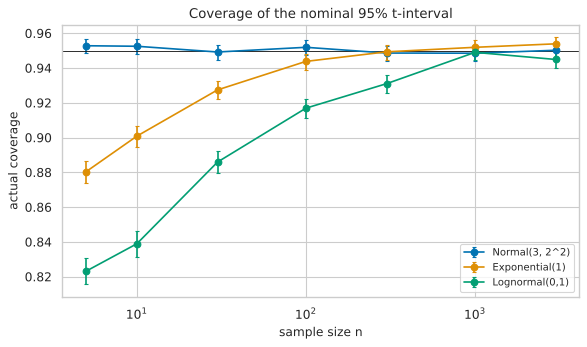

PosixPath('/home/claude/probability-simulation-laboratory/04_central_limit_theorem/results/exp4_4_coverage.png')

In [8]:
# F. Implementation ------------------------------------------------------------------
cov_laws = {"Normal(3, 2^2)": stats.norm(3, 2), "Exponential(1)": stats.expon(), "Lognormal(0,1)": stats.lognorm(s=1.0)}
n_list = [5, 10, 30, 100, 300, 1000, 3000]
rows = []
for name, dist in cov_laws.items():
    draw, mu, _ = clt.from_frozen(dist)
    for n in n_list:
        c = clt.student_t_coverage(draw, mu, n, 10_000, rng)
        lo, hi = wilson_interval(int(round(c * 10_000)), 10_000)
        rows.append(dict(distribution=name, n=n, coverage=c, wilson_low=lo, wilson_high=hi))
cov = pd.DataFrame(rows)
cov.to_csv(RESULTS / "exp4_4_coverage.csv", index=False)

# G. Results -----------------------------------------------------------------------------
display(cov.pivot(index="n", columns="distribution", values="coverage").round(4))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name in cov_laws:
    sub = cov[cov.distribution == name]
    ax.errorbar(sub.n, sub.coverage, yerr=[sub.coverage - sub.wilson_low, sub.wilson_high - sub.coverage], fmt="o-", capsize=2, label=name)
ax.axhline(0.95, color="k", lw=0.8)
ax.set(xscale="log", xlabel="sample size n", ylabel="actual coverage", title="Coverage of the nominal 95% t-interval")
ax.legend(); fig.tight_layout(); save_fig(fig, RESULTS, "exp4_4_coverage.png")

**H. Theoretical versus empirical comparison.**

Normal data: coverage is $0.949$–$0.953$ for all $n$, within Monte Carlo error of $0.95$ (the interval is exact). Exponential: $0.880$ at $n=5$, $0.901$ at $n=10$, $0.927$ at $n=30$, $0.944$ at $n=100$ and about $0.95$ from $n\approx300$. Lognormal(0,1): $0.823$ at $n=5$, $0.886$ at $n=30$, $0.917$ at $n=100$, $0.931$ at $n=300$, and only about $0.95$ by $n\approx1000$ — consistent with the slow CLT convergence found in Experiments 4.1–4.2.

**I. Interpretation.**

A "95% interval" is a *property of a procedure under a model*. Under skewness the actual coverage can be far from 95%, with errors that are one-sided (the interval undercovers because the sample mean is usually below $\mu$ and extreme values that push $\bar X$ up are rare). In applications such as backtests of strategy returns, which are skewed and heavy-tailed, the stated confidence of mean-based intervals is optimistic.

**J. Limitations.**

Only three distributions and a single interval type. The bootstrap-$t$ or percentile intervals would behave differently. Coverage is estimated with $10{,}000$ replications: $\pm0.4$ percentage points at the 95% level.

**K. Research conclusion.**

The CLT justifies the $t$-interval asymptotically; for skewed data actual coverage lags the nominal level for a long time.

**L. Further investigation.**

Compare against the bootstrap percentile and bootstrap-$t$ intervals (resample the data; Module 5 introduces resampling for error estimation).

## Exercises (paper first)

1. Verify that $Z_n$ has mean $0$ and variance $1$ for every $n$. Which assumption provides the variance statement?
2. Use the characteristic-function sketch to show the CLT for sums of i.i.d. Bernoulli($p$) — i.e. the de Moivre–Laplace theorem. How large must $np$ and $n(1-p)$ be for the normal approximation to the Binomial to be accurate? Test with simulation.
3. If daily returns have standard deviation $1\%$, what is the standard deviation of the 252-day average return? What is the probability (under the CLT) that the annual average daily return differs from its mean by more than $0.1\%$?
4. Show $\operatorname{skew}(\bar X_n)=\gamma/\sqrt n$ from $\kappa_3(\sum X_i)=n\kappa_3(X)$ (additivity of cumulants).
5. Why is the CLT *not* a statement about the distribution of the data itself?
6. Give an example of i.i.d. data with finite mean but infinite variance. What is the right scaling for $\bar X_n$?
7. Explain why a "95% confidence interval" for the mean of a skewed distribution can systematically undercover. How would you detect this by simulation?

## Summary of Module 4
* Standardised sample means converge in distribution to $\mathcal N(0,1)$ when the variance is finite.
* Rate: $O(n^{-1/2})$ for skewed data; skewness of $Z_n=\gamma/\sqrt n$.
* Infinite variance changes the scaling; heavy tails cripple the normal approximation in the tails even with finite variance.
* Confidence-interval coverage is only approximately nominal for non-normal data.

**Next:** Module 5 — Monte Carlo simulation.